<a href="https://colab.research.google.com/github/d3m1d0s/FoML_projects/blob/main/project_1/bankchurners_eda_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Fundamentals of Machine Learning, Project 1**

### Exploratory and Cluster Analysis: Credit Card Customers

Author: Demid Ostiakov (OST0059)  
Dataset: [Credit Card Customers (Kaggle)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/d3m1d0s/FoML_projects/main/project_1/BankChurners.csv/BankChurners.csv"

df = pd.read_csv(DATA_URL)

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> First Look at the Data </font></h2>
</div>

Display the first and last 20 rows of the dataset.

In [3]:
# show all columns instead of hiding the middle ones
pd.set_option("display.max_columns", None)

display(df.head(20))

display(df.tail(20))

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998
5,713061558,Existing Customer,44,M,2,Graduate,Married,$40K - $60K,Blue,36,3,1,2,4010.0,1247,2763.0,1.376,1088,24,0.846,0.311,0.000055,0.99994
6,810347208,Existing Customer,51,M,4,Unknown,Married,$120K +,Gold,46,6,1,3,34516.0,2264,32252.0,1.975,1330,31,0.722,0.066,0.000123,0.99988
7,818906208,Existing Customer,32,M,0,High School,Unknown,$60K - $80K,Silver,27,2,2,2,29081.0,1396,27685.0,2.204,1538,36,0.714,0.048,0.000086,0.99991
8,710930508,Existing Customer,37,M,3,Uneducated,Single,$60K - $80K,Blue,36,5,2,0,22352.0,2517,19835.0,3.355,1350,24,1.182,0.113,0.000045,0.99996
9,719661558,Existing Customer,48,M,2,Graduate,Single,$80K - $120K,Blue,36,6,3,3,11656.0,1677,9979.0,1.524,1441,32,0.882,0.144,0.000303,0.99970


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
10107,713924283,Attrited Customer,61,M,0,Graduate,Single,$60K - $80K,Blue,54,2,1,4,11859.0,1644,10215.0,0.866,8930,79,0.837,0.139,0.992680,0.007320
10108,714471183,Attrited Customer,47,M,4,Graduate,Divorced,$80K - $120K,Blue,39,4,3,4,17504.0,476,17028.0,0.892,10468,66,0.737,0.027,0.998160,0.001844
10109,780613758,Existing Customer,47,M,5,High School,Single,Less than $40K,Blue,35,4,3,5,4165.0,0,4165.0,0.813,17093,111,0.820,0.000,0.000896,0.999100
10110,718225683,Existing Customer,56,M,1,Graduate,Single,$80K - $120K,Silver,49,5,2,2,34516.0,1091,33425.0,0.640,15274,108,0.714,0.032,0.000097,0.999900
10111,710734308,Existing Customer,49,M,1,Graduate,Single,$60K - $80K,Blue,40,6,3,3,6481.0,1569,4912.0,0.692,15937,119,0.803,0.242,0.000284,0.999720
10112,708564858,Attrited Customer,33,M,2,College,Married,$120K +,Gold,20,2,1,4,34516.0,0,34516.0,1.004,9338,73,0.622,0.000,0.994380,0.005620
10113,713733633,Attrited Customer,27,M,0,High School,Divorced,$60K - $80K,Blue,36,2,3,2,13303.0,2517,10786.0,0.929,10219,85,0.809,0.189,0.993380,0.006620
10114,720841533,Existing Customer,29,M,0,Graduate,Married,Less than $40K,Blue,15,3,1,5,4700.0,0,4700.0,0.617,14723,96,0.655,0.000,0.000235,0.999770
10115,712210458,Existing Customer,38,M,1,Uneducated,Single,$40K - $60K,Blue,36,2,3,2,5639.0,1558,4081.0,0.614,16628,109,0.946,0.276,0.000174,0.999830
10116,714109308,Existing Customer,46,M,5,College,Single,$80K - $120K,Blue,36,1,2,3,13187.0,2241,10946.0,0.689,15354,112,0.931,0.170,0.000192,0.999810


The first and last rows look quite different. Among the first 20 customers there is no closed account, while 10 of the last 20 are attrited. The rows are therefore not in random order, and the file seems to be sorted in some way. A few rows from one end of the file are not a representative sample, so conclusions should always be based on the whole dataset, and any sampling or splitting later on has to be random.

Each row describes one credit card customer of the bank: who they are (age, gender, education, income), which card they hold, and how they used it over the last 12 months.

Column descriptions, based on the dataset's Kaggle page:
- `CLIENTNUM`: unique customer ID.
- `Attrition_Flag`: whether the customer closed the account ("Attrited Customer") or is still active ("Existing Customer").
- `Customer_Age`: age in years.
- `Gender`: M or F.
- `Dependent_count`: number of dependents.
- `Education_Level`: educational qualification (Uneducated, High School, College, Graduate, Post-Graduate, Doctorate or Unknown).
- `Marital_Status`: Married, Single, Divorced or Unknown.
- `Income_Category`: annual income band, from "Less than \$40K" to "\$120K +", or Unknown.
- `Card_Category`: card type (Blue, Silver, Gold or Platinum).
- `Months_on_book`: how many months the customer has been with the bank.
- `Total_Relationship_Count`: number of bank products the customer holds.
- `Months_Inactive_12_mon`: number of months the customer was inactive in the last 12 months. The page does not define what counts as inactive.
- `Contacts_Count_12_mon`: number of contacts in the last 12 months. The page does not say who initiated them.
- `Credit_Limit`: credit limit on the card.
- `Total_Revolving_Bal`: balance carried over to the next month, i.e. the unpaid part of the debt.
- `Avg_Open_To_Buy`: credit still available to spend, averaged over the last 12 months.
- `Total_Amt_Chng_Q4_Q1`: total transaction amount in Q4 divided by the amount in Q1. Values below 1 mean the customer spent less in Q4 than in Q1.
- `Total_Trans_Amt`: total amount spent in the last 12 months.
- `Total_Trans_Ct`: number of transactions in the last 12 months.
- `Total_Ct_Chng_Q4_Q1`: number of transactions in Q4 divided by the number in Q1.
- `Avg_Utilization_Ratio`: average share of the credit limit the customer uses.
- `Naive_Bayes_Classifier_..._1` and `..._2`: described only as "Naive Bayes". According to their names, they are outputs of a Naive Bayes classifier for `Attrition_Flag`, so they are not customer data.

The target is `Attrition_Flag`. "Attrited Customer" means the customer closed the account, while "Existing Customer" means they stayed. In this project it is not used to build clusters, only to compare them later and see if some groups have more closed accounts than others.

Check the basic information about the DataFrame.

In [4]:
cut_df = df.rename(columns=lambda x: x[:30] + '...' if len(x) > 30 else x)

cut_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   CLIENTNUM                          10127 non-null  int64  
 1   Attrition_Flag                     10127 non-null  object 
 2   Customer_Age                       10127 non-null  int64  
 3   Gender                             10127 non-null  object 
 4   Dependent_count                    10127 non-null  int64  
 5   Education_Level                    10127 non-null  object 
 6   Marital_Status                     10127 non-null  object 
 7   Income_Category                    10127 non-null  object 
 8   Card_Category                      10127 non-null  object 
 9   Months_on_book                     10127 non-null  int64  
 10  Total_Relationship_Count           10127 non-null  int64  
 11  Months_Inactive_12_mon             10127 non-null  int

The dataset has 10,127 rows and 23 columns. According to `info()`, there are no missing values, as every column has 10,127 non-null entries. However, `head()` already shows the value "Unknown" in `Marital_Status` (row 3), so some missing information may be stored as text instead of NaN. This is checked later.

Some numerical columns are counts rather than continuous measurements. Judging by the first rows, they fall into two groups, and the exact number of values in each column is checked in the Variable Types section.
- `Dependent_count`, `Total_Relationship_Count`, `Months_Inactive_12_mon` and `Contacts_Count_12_mon` seem to take only a few small values. Each value then forms a large group of customers, so these columns are best explored value by value, with frequency tables (how many customers have each value) and bar charts.
- `Total_Trans_Ct` and `Months_on_book` seem to take many different values. A single value then contains only a few customers and neighbouring values hardly differ, so these columns are better treated as continuous and explored with histograms and quantiles.

Three columns are not real customer features and will be removed:
- `CLIENTNUM`, because it only identifies the customer. It is stored as `int64`, but its value carries no numerical meaning.
- The two `Naive_Bayes_Classifier_...` columns. They are the output of a classifier trained on `Attrition_Flag`, so they effectively contain the answer. The dataset author also recommends deleting them.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Duplicates and Column Cleanup </font></h2>
</div>

Before removing `CLIENTNUM`, we use it to check for duplicates. There are three basic cases:
- the same row appears more than once,
- the same customer ID appears more than once,
- two rows with different IDs contain exactly the same customer data.

In [5]:
full_row_dups = df.duplicated().sum()
id_dups = df["CLIENTNUM"].duplicated().sum()
data_dups = df.drop(columns=["CLIENTNUM"]).duplicated().sum()

print("Fully duplicated rows:", full_row_dups)
print("Duplicated customer IDs:", id_dups)
print("Duplicated rows ignoring the ID:", data_dups)

Fully duplicated rows: 0
Duplicated customer IDs: 0
Duplicated rows ignoring the ID: 0


The check confirmed that there are no duplicates of any kind in the dataset, so no further cleaning is required in this regard.

Now we remove the columns that are not real customer features: the ID and the two Naive Bayes columns.

In [6]:
nb_cols = [col for col in df.columns if col.startswith("Naive_Bayes")]

df = df.drop(columns=["CLIENTNUM"] + nb_cols)

print("Removed:", ["CLIENTNUM"] + nb_cols)
print("Shape after removal:", df.shape)

Removed: ['CLIENTNUM', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Shape after removal: (10127, 20)


After the removal, the dataset has 10,127 rows and 20 columns. One of them, `Attrition_Flag`, is the target. It stays in the dataset, but it will not be used as an input for clustering, only to describe the clusters afterwards. This leaves 19 columns that describe the customers themselves. Whether all of them are needed is not settled yet, since some may carry the same information as others.

Some columns may be calculated from other columns, and then they add no new information. Two candidates follow from the column descriptions. `Avg_Open_To_Buy` is the credit still available, which should be the limit minus the balance. `Avg_Utilization_Ratio` is the share of the limit in use, which should be the balance divided by the limit. Both relationships are checked on every row. The ratio is stored with three decimals, so it is compared with a tolerance of 0.0005.

In [7]:
open_to_buy_calc = df["Credit_Limit"] - df["Total_Revolving_Bal"]
utilization_calc = df["Total_Revolving_Bal"] / df["Credit_Limit"]

open_to_buy_match = np.isclose(df["Avg_Open_To_Buy"], open_to_buy_calc).sum()
utilization_match = np.isclose(df["Avg_Utilization_Ratio"], utilization_calc, atol=0.0005).sum()

print("Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal:", open_to_buy_match, "of", len(df), "rows")
print("Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit:", utilization_match, "of", len(df), "rows")

Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal: 10127 of 10127 rows
Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit: 10127 of 10127 rows


Both relationships hold for every customer, and despite the "Avg" in their names, neither column is an average over 12 months. Both are direct calculations from the limit and the balance.

`Avg_Open_To_Buy` is exactly the credit limit minus the revolving balance. It adds no information, and in clustering it would only give the limit and the balance extra weight in the distance between customers.

`Avg_Utilization_Ratio` is the balance divided by the limit. It is also fully determined by two columns we keep, so it is removed as well.

Both columns are still easy to read, for example "uses 70% of the limit" or "has 5,000 of credit left". They will not be used as clustering inputs, but they will be recomputed from `Credit_Limit` and `Total_Revolving_Bal` and added to the final cluster profiles, where they help describe who the customers in each cluster are.

In [8]:
df = df.drop(columns=["Avg_Open_To_Buy", "Avg_Utilization_Ratio"])

print("Shape after removal:", df.shape)

Shape after removal: (10127, 18)


The dataset now has 18 columns: the target `Attrition_Flag` and 17 customer features.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Hidden Missing Values </font></h2>
</div>

According to `info()`, the dataset has no missing values, but the first rows already contain the value "Unknown". First we check how often it appears in each text column.

In [9]:
text_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]

unknown_counts = (df[text_cols] == "Unknown").sum()
display(unknown_counts)

,0
Attrition_Flag,0
Gender,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0


"Unknown" appears only in `Education_Level`, `Marital_Status` and `Income_Category`. The other text columns are complete.

In these three columns "Unknown" does not describe the customer. It only says that the bank does not have the information, so it is a missing value stored as text. As long as it stays a normal string, pandas counts it as an ordinary category, and it would also have to be placed somewhere in the natural order of education and income levels, where it does not belong. We therefore replace it with NaN, so that it is treated as missing.

In [10]:
df = df.replace("Unknown", np.nan)

In [11]:
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(1)
})
display(missing_summary[missing_summary["Missing count"] > 0])

rows_with_missing = df.isna().any(axis=1).sum()
print("Rows with at least one missing value:", rows_with_missing, f"({rows_with_missing / len(df) * 100:.1f}%)")

,Missing count,Missing percentage
Education_Level,1519,15.0
Marital_Status,749,7.4
Income_Category,1112,11.0


Rows with at least one missing value: 3046 (30.1%)


Education is missing for 15.0% of customers, income for 11.0% and marital status for 7.4%. Together, 3,046 customers (30.1%) have at least one missing value.

Removing incomplete rows would therefore cost almost a third of the dataset, and it could also bias the analysis if customers with missing information differ from the others. Removing whole columns is not justified either, because each of them is still known for most customers. How to handle the missing values in each column is decided later, after we have seen whether customers with missing information behave differently, for example whether they close their accounts more often.

Next we check whether the missing values fall on the same customers, for example because some records are incomplete as a whole. If the gaps in two columns are unrelated, the number of customers missing both is close to what chance alone would give: the share missing in the first column times the share missing in the second, times the number of customers.

In [12]:
from itertools import combinations

miss_cols = ["Education_Level", "Marital_Status", "Income_Category"]
missing_flags = df[miss_cols].isna()

display(missing_flags.sum(axis=1).value_counts().sort_index()
        .rename_axis("Missing values per customer").to_frame("Customers"))

pair_rows = []
for col_a, col_b in combinations(miss_cols, 2):
    pair_rows.append({
        "Columns": f"{col_a} + {col_b}",
        "Missing in both": (missing_flags[col_a] & missing_flags[col_b]).sum(),
        "Expected by chance": round(missing_flags[col_a].mean() * missing_flags[col_b].mean() * len(df))
    })

display(pd.DataFrame(pair_rows).set_index("Columns"))

,Customers
Missing values per customer,
0,7081
1,2719
2,320
3,7


,Missing in both,Expected by chance
Columns,,
Education_Level + Marital_Status,114,112
Education_Level + Income_Category,145,167
Marital_Status + Income_Category,82,82


Most incomplete customers miss only one value (2,719), 320 miss two and only 7 miss all three. For every pair of columns, the number of customers missing both is close to what chance would give (114 vs 112, 145 vs 167 and 82 vs 82). The gaps are therefore spread over the customers independently, and there is no group of generally incomplete records. Each column can be handled separately, and removing incomplete rows would make even less sense.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Variable Types </font></h2>
</div>

A pandas dtype only shows how the values are stored, not what they mean. Before any statistics or plots, each column is classified by its statistical type, because the type decides which summaries, plots and encodings make sense.

First, the numerical columns: how many different values each of them has and what range they cover.

In [13]:
num_cols = df.select_dtypes(include="number").columns

num_overview = pd.DataFrame({
    "Dtype": df[num_cols].dtypes,
    "Unique values": df[num_cols].nunique(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max()
})
display(num_overview)

,Dtype,Unique values,Min,Max
Customer_Age,int64,45,26.0,73.000
Dependent_count,int64,6,0.0,5.000
Months_on_book,int64,44,13.0,56.000
Total_Relationship_Count,int64,6,1.0,6.000
Months_Inactive_12_mon,int64,7,0.0,6.000
Contacts_Count_12_mon,int64,7,0.0,6.000
Credit_Limit,float64,6205,1438.3,34516.000
Total_Revolving_Bal,int64,1974,0.0,2517.000
Total_Amt_Chng_Q4_Q1,float64,1158,0.0,3.397
Total_Trans_Amt,int64,5033,510.0,18484.000


Four columns have only a handful of values: `Dependent_count` and `Total_Relationship_Count` have 6, `Months_Inactive_12_mon` and `Contacts_Count_12_mon` have 7. These are the small counts. `Customer_Age`, `Months_on_book` and `Total_Trans_Ct` are also whole numbers, but with 45, 44 and 126 different values. The remaining five columns are amounts and ratios with hundreds to thousands of different values, so they are clearly continuous.

The line between a count and a count treated as continuous is a rule of thumb of roughly 10 different values. Here every column is clearly on one side, with at most 7 or at least 44 values. The distinction only matters for exploring the data, not for clustering.

Together with the column descriptions, this gives the following classification:

| Variable | Pandas dtype | Statistical type |
| --- | --- | --- |
| `Attrition_Flag` | object | binary, target |
| `Customer_Age` | int64 | numerical, treated as continuous |
| `Gender` | object | nominal (binary) |
| `Dependent_count` | int64 | count (0 to 5) |
| `Education_Level` | object | ordinal |
| `Marital_Status` | object | nominal |
| `Income_Category` | object | ordinal (income bands) |
| `Card_Category` | object | ordinal (card tiers) |
| `Months_on_book` | int64 | count, treated as continuous |
| `Total_Relationship_Count` | int64 | count (1 to 6) |
| `Months_Inactive_12_mon` | int64 | count (0 to 6) |
| `Contacts_Count_12_mon` | int64 | count (0 to 6) |
| `Credit_Limit` | float64 | continuous |
| `Total_Revolving_Bal` | int64 | continuous |
| `Total_Amt_Chng_Q4_Q1` | float64 | continuous (ratio Q4 / Q1) |
| `Total_Trans_Amt` | int64 | continuous |
| `Total_Trans_Ct` | int64 | count, treated as continuous |
| `Total_Ct_Chng_Q4_Q1` | float64 | continuous (ratio Q4 / Q1) |

The text columns are checked the same way, with all their values and how often they occur. Missing values are shown as NaN.

In [14]:
for col in text_cols:
    display(df[col].value_counts(dropna=False))

,count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


,count
Gender,
F,5358
M,4769


,count
Education_Level,
Graduate,3128
High School,2013
NaN,1519
Uneducated,1487
College,1013
Post-Graduate,516
Doctorate,451


,count
Marital_Status,
Married,4687
Single,3943
NaN,749
Divorced,748


,count
Income_Category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
NaN,1112
$120K +,727


,count
Card_Category,
Blue,9436
Silver,555
Gold,116
Platinum,20


`Attrition_Flag` has two values and is the binary target. `Gender` (F and M) and `Marital_Status` (Married, Single and Divorced) have no natural order, so they are nominal. `Education_Level` (six levels from Uneducated to Doctorate), `Income_Category` (five income bands) and `Card_Category` (Blue, Silver, Gold and Platinum) do have a natural order, so they are ordinal. `Card_Category` is very unbalanced: 9,436 customers (93.2%) hold a Blue card and only 20 a Platinum card.

The numerical columns are already stored correctly. The text columns are all stored as plain `object`, which does not distinguish between nominal and ordinal variables, and the target is stored as text. These are converted next.

The target is replaced by a new column `Churned`, where 1 means the customer closed the account and 0 means they stayed. With this encoding, the mean of `Churned` in any group is directly the churn rate of that group.

In [15]:
df["Churned"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
df = df.drop(columns=["Attrition_Flag"])

df["Churned"].value_counts()

,count
Churned,
0,8500
1,1627


The ordinal columns get an explicit order, so that pandas sorts them and compares them by meaning and not alphabetically. The nominal columns become plain categories. Missing values stay NaN, because they are not part of any order.

In [16]:
education_order = ["Uneducated", "High School", "College", "Graduate", "Post-Graduate", "Doctorate"]
income_order = ["Less than $40K", "$40K - $60K", "$60K - $80K", "$80K - $120K", "$120K +"]
card_order = ["Blue", "Silver", "Gold", "Platinum"]

df["Education_Level"] = pd.Categorical(df["Education_Level"], categories=education_order, ordered=True)
df["Income_Category"] = pd.Categorical(df["Income_Category"], categories=income_order, ordered=True)
df["Card_Category"] = pd.Categorical(df["Card_Category"], categories=card_order, ordered=True)

df["Gender"] = df["Gender"].astype("category")
df["Marital_Status"] = df["Marital_Status"].astype("category")

A value that is not listed in the order would silently become NaN. To make sure nothing was lost, the missing counts must be the same as before the conversion (1519,  749 and 1112).

In [17]:
cat_cols = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]

display(df[cat_cols].isna().sum())
display(df.info())
print('Churned:', round(df['Churned'].mean(),3))

,0
Gender,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Customer_Age              10127 non-null  int64   
 1   Gender                    10127 non-null  category
 2   Dependent_count           10127 non-null  int64   
 3   Education_Level           8608 non-null   category
 4   Marital_Status            9378 non-null   category
 5   Income_Category           9015 non-null   category
 6   Card_Category             10127 non-null  category
 7   Months_on_book            10127 non-null  int64   
 8   Total_Relationship_Count  10127 non-null  int64   
 9   Months_Inactive_12_mon    10127 non-null  int64   
 10  Contacts_Count_12_mon     10127 non-null  int64   
 11  Credit_Limit              10127 non-null  float64 
 12  Total_Revolving_Bal       10127 non-null  int64   
 13  Total_Amt_Chng_Q4_Q1      10127 non-null  floa

None

Churned: 0.161


`Churned` has 1,627 customers with value 1 and 8,500 with value 0, so 16.1% of the customers closed their account. The missing counts are unchanged, which means every known value matched one of the listed categories and the conversion lost nothing.

The dataset now consists of 12 numerical columns, 5 categorical columns (3 of them ordered) and the binary target `Churned`.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Univariate Analysis: Continuous Variables </font></h2>
</div>

This section looks at each continuous variable on its own: its centre, spread, shape and unusual values. The small counts and the categorical variables follow in a separate section.

In [18]:
cont_cols = ["Customer_Age", "Months_on_book", "Credit_Limit", "Total_Revolving_Bal",
             "Total_Amt_Chng_Q4_Q1", "Total_Trans_Amt", "Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1"]

### Descriptive statistics

Besides the usual summary, the table includes skewness. A value close to 0 means a roughly symmetric distribution, a positive value means a right-skewed distribution with a long right tail, and a negative value a left-skewed one with a long left tail.

In [19]:
cont_summary = df[cont_cols].describe().T
cont_summary["skew"] = df[cont_cols].skew()

display(cont_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skew
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00,-0.03
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00,-0.11
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00,1.67
Total_Revolving_Bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00,-0.15
Total_Amt_Chng_Q4_Q1,10127.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40,1.73
Total_Trans_Amt,10127.0,4404.09,3397.13,510.0,2155.50,3899.00,4741.00,18484.00,2.04
Total_Trans_Ct,10127.0,64.86,23.47,10.0,45.00,67.00,81.00,139.00,0.15
Total_Ct_Chng_Q4_Q1,10127.0,0.71,0.24,0.0,0.58,0.70,0.82,3.71,2.06


Four variables are strongly right-skewed (skewness above 1.5): `Credit_Limit`, `Total_Trans_Amt`, `Total_Amt_Chng_Q4_Q1` and `Total_Ct_Chng_Q4_Q1`. For `Credit_Limit` the mean is almost twice the median (8,632 vs 4,549), and for `Total_Trans_Amt` it is also clearly higher (4,404 vs 3,899). For the two Q4/Q1 ratios the mean is only slightly above the median (0.76 vs 0.74 and 0.71 vs 0.70), even though their skewness is the highest. The reason is checked on the histograms.

`Customer_Age`, `Months_on_book` and `Total_Trans_Ct` look roughly symmetric, with skewness close to 0 and the mean close to the median. `Total_Revolving_Bal` also has a skewness close to 0, but its mean is below the median (1,163 vs 1,276), so its shape is checked on the histogram as well.

For the right-skewed variables, the median and the IQR describe a typical customer better than the mean and the standard deviation.

### Distributions

Histograms show the full shape of each distribution, which the summary table cannot. `Customer_Age`, `Months_on_book` and `Total_Trans_Ct` contain only whole numbers, so they get one bar per value. With a fixed number of bins, some bins would contain one whole number and others two, which creates spikes that do not exist in the data.

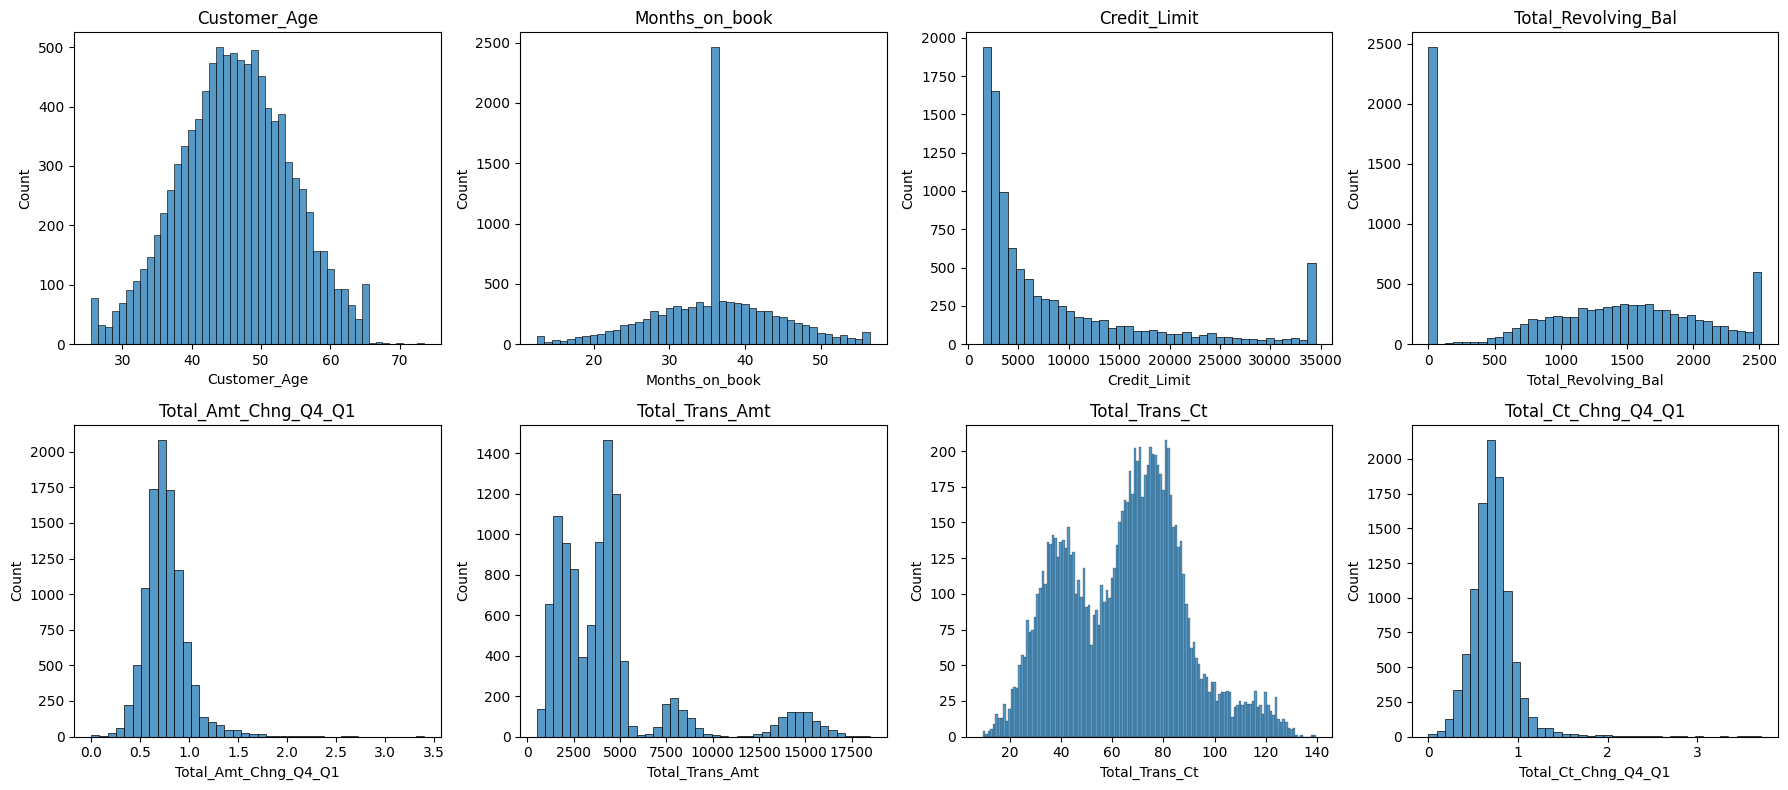

In [20]:
int_cols = ["Customer_Age", "Months_on_book", "Total_Trans_Ct"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, cont_cols):
    if col in int_cols:
        sns.histplot(data=df, x=col, discrete=True, ax=ax)
    else:
        sns.histplot(data=df, x=col, bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The histograms confirm the skewness for some variables, but they also show shapes that a single number cannot describe:
- `Customer_Age` is symmetric and bell-shaped.
- `Months_on_book` is roughly symmetric too, apart from one huge spike at around 36 months.
- `Total_Trans_Ct` is not a single bell, even though its skewness is close to 0. It has two peaks, one around 40 transactions and another around 70 to 80.
- `Credit_Limit` is right-skewed, with most customers at the lower end and a long tail, plus a separate pile at the maximum.
- `Total_Revolving_Bal` has three parts: a large group at zero, a bell-shaped middle part and a pile at the maximum. Its skewness is close to 0 only because these parts balance each other, and the group at zero explains why its mean is below the median.
- `Total_Amt_Chng_Q4_Q1` and `Total_Ct_Chng_Q4_Q1` have a narrow peak around 0.7 and a long, thin tail to the right. Only a few customers lie in the tail, so the mean barely moves, while the skewness reacts strongly.
- `Total_Trans_Amt` is right-skewed and has several separate groups: most customers spend less than about 5,500 (with two peaks of their own), a smaller group spends around 7,000 to 9,000, and another around 13,000 to 16,000.

Several of these patterns need an explanation:
- **The spike in `Months_on_book`:** about 2,500 customers have this single value, while its neighbours have only a few hundred each. A real wave of new customers would spread over several months, so this is more likely a default value used when the opening date was unknown, or a large one-time acquisition. The data cannot tell which, so the value is kept, but these customers are treated with caution.
- **Zero revolving balance:** about 2,500 customers carry no balance. In a credit card portfolio these are usually customers who pay their bill in full every month, or who barely use the card.
- **Piles at the maximum of `Credit_Limit` and `Total_Revolving_Bal`:** both have a separate bar at their highest value, much taller than the bars before it. A highest credit limit offered by the bank could explain the pile in `Credit_Limit`, but not the one in `Total_Revolving_Bal`, because a balance is already bounded by each customer's own credit limit. Smaller piles of the same kind appear at both ends of `Customer_Age` (near 26 and 65) and `Months_on_book` (13 and 56). The values were therefore most likely capped when the dataset was prepared, so everything above a certain boundary was replaced by the boundary itself. For the customers in these piles, the real value is unknown, only that it is at least as extreme as the boundary.
- **Groups in `Total_Trans_Amt` and two peaks in `Total_Trans_Ct`:** the customers seem to form distinct groups with low and high card activity. This is a first hint of natural groups for the cluster analysis, and the bivariate analysis will show whether churn differs between them.

The spike in `Months_on_book` and the group with zero revolving balance are both large. If they were mostly the same customers, both patterns could come from one source, for example accounts that were filled with default values. This is checked by comparing the two groups directly.

In [21]:
spike_36 = df["Months_on_book"] == 36
zero_balance = df["Total_Revolving_Bal"] == 0

overlap = pd.crosstab(
    spike_36.map({True: "36 months", False: "Other"}),
    zero_balance.map({True: "Zero balance", False: "Non-zero balance"}),
    margins=True,
    margins_name="Total"
)
overlap.index.name = None
overlap.columns.name = None
overlap["Zero balance (%)"] = (overlap["Zero balance"] / overlap["Total"] * 100).round(1)

display(overlap)

,Non-zero balance,Zero balance,Total,Zero balance (%)
36 months,1839,624,2463,25.3
Other,5818,1846,7664,24.1
Total,7657,2470,10127,24.4


Only 624 customers belong to both groups. Among the customers with 36 months, 25.3% have a zero balance, almost the same share as among all other customers (24.1%). The two patterns are therefore independent of each other and separate.

### Potential outliers

Boxplots summarise the median, the quartiles and the points outside the whiskers, which are 1.5 IQR below Q1 and above Q3.

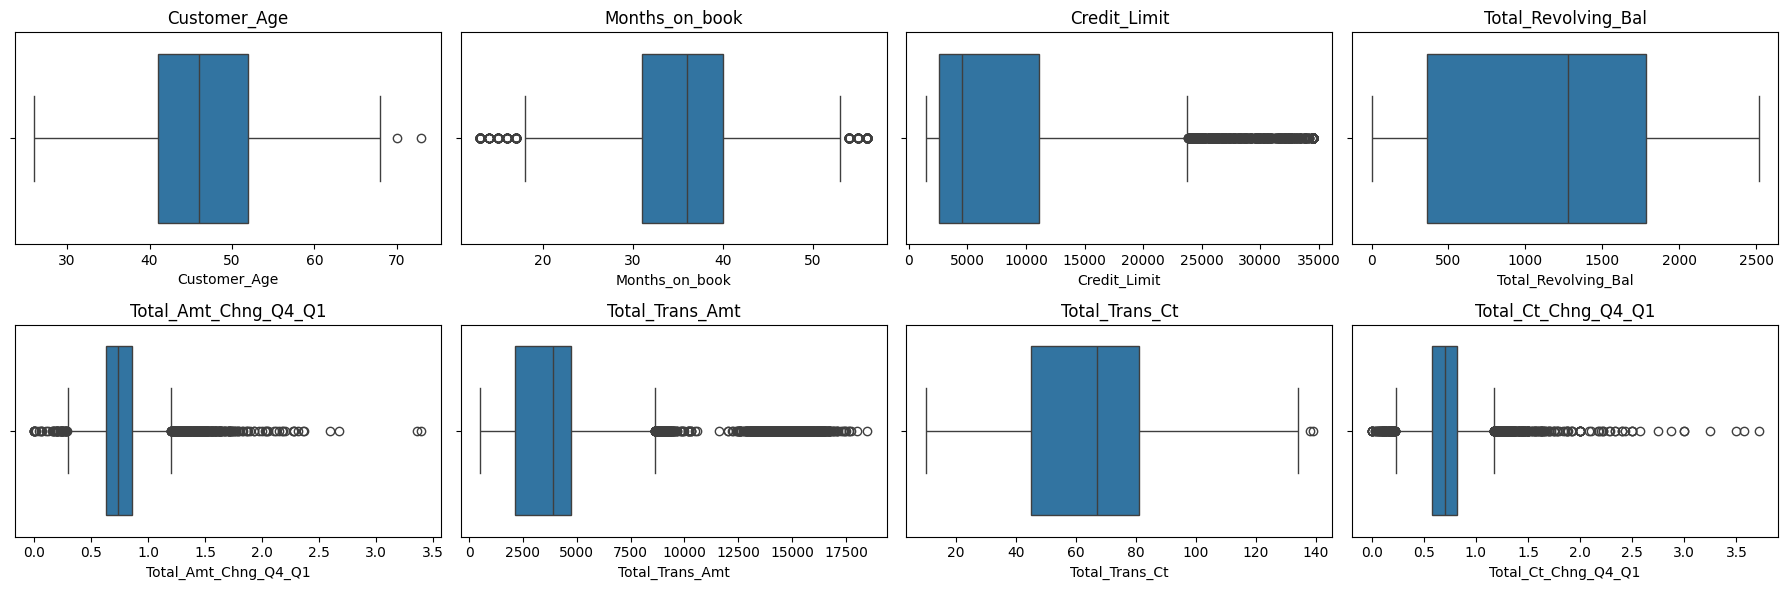

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))

for ax, col in zip(axes.flat, cont_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The same IQR rule, counted for each variable:

In [23]:
outlier_rows = []

for col in cont_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    outlier_rows.append({
        "Variable": col,
        "Lower fence": lower_fence,
        "Upper fence": upper_fence,
        "Potential outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("Variable")
display(outlier_summary.round(2))

,Lower fence,Upper fence,Potential outliers,Percentage
Variable,,,,
Customer_Age,24.50,68.50,2,0.02
Months_on_book,17.50,53.50,386,3.81
Credit_Limit,-10213.75,23836.25,984,9.72
Total_Revolving_Bal,-1778.50,3921.50,0,0.00
Total_Amt_Chng_Q4_Q1,0.29,1.20,396,3.91
Total_Trans_Amt,-1722.75,8619.25,896,8.85
Total_Trans_Ct,-9.00,135.00,2,0.02
Total_Ct_Chng_Q4_Q1,0.23,1.17,394,3.89


Most potential outliers are in `Credit_Limit` (984 customers, 9.72%) and `Total_Trans_Amt` (896, 8.85%), followed by the two Q4/Q1 ratios and `Months_on_book` with just under 4% each. `Customer_Age` and `Total_Trans_Ct` have only 2 each, and `Total_Revolving_Bal` has none.

Compared with the histograms, these are mostly not isolated points but whole parts of the distributions:
- `Credit_Limit`: the long right tail and the pile at the maximum.
- `Total_Trans_Amt`: the separate groups of customers who spend much more than the rest.
- The Q4/Q1 ratios: customers whose activity dropped sharply or grew strongly in Q4 compared with Q1. A sharp drop could come before closing an account.
- `Total_Revolving_Bal`: no outliers by the IQR rule, although its group at zero and the pile at the maximum are clearly unusual.

No values are removed, including the piles and the spike in `Months_on_book`, because they describe real groups of customers rather than mistakes. Whether the outliers are related to churn is checked in the bivariate analysis, and their influence on K-means is reduced later by transforming the skewed variables instead of deleting customers.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Univariate Analysis: Counts and Categorical Variables </font></h2>
</div>

The small counts and the categorical variables have only a few values each, so they are explored value by value. Each bar shows the share of customers with that value, which makes variables with different numbers of values easy to compare. Missing values are added as a separate bar "Missing". Boxplots and the IQR rule are not used here. Categorical variables have no distances between their values, and for counts with only a few values the IQR rule would simply flag the lowest and highest values as outliers, although the bar charts already show exactly how rare they are.

In [24]:
def plot_shares(cols, figsize, rotation=0):
    fig, axes = plt.subplots(1, len(cols), figsize=figsize)

    for ax, col in zip(axes, cols):
        shares = df[col].value_counts().sort_index() / len(df) * 100
        # escape "$", otherwise matplotlib reads "$40K - $60K" as a formula
        shares.index = shares.index.astype(str).str.replace("$", r"\$", regex=False)
        if df[col].isna().any():
            shares["Missing"] = df[col].isna().mean() * 100

        bars = ax.bar(shares.index, shares.values)
        ax.bar_label(bars, fmt="%.1f")
        ax.margins(y=0.1)
        ax.set_title(col)
        ax.set_ylabel("Share of customers (%)")
        ax.tick_params(axis="x", rotation=rotation)

    plt.tight_layout()
    plt.show()

### Small counts

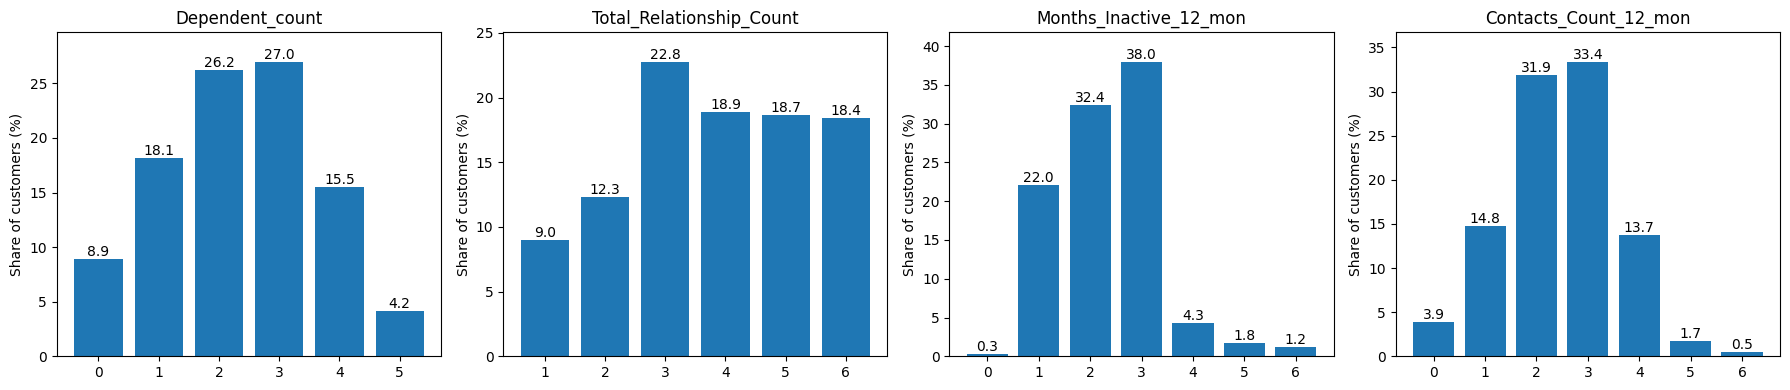

In [25]:
count_cols = ["Dependent_count", "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon"]

plot_shares(count_cols, figsize=(18, 4))

All four counts are concentrated on a few middle values:
- `Dependent_count`: most customers have 2 or 3 dependents (26.2% and 27.0%), while 0 and 5 are the rarest values.
- `Total_Relationship_Count`: 3 products is the most common value (22.8%), and 4, 5 and 6 products are almost equally common. Only 9.0% of the customers hold a single product, so most of them use several products of the bank.
- `Months_Inactive_12_mon`: almost all customers were inactive for 1 to 3 months (22.0%, 32.4% and 38.0%), and 4 or more months are rare.
- `Contacts_Count_12_mon`: 2 or 3 contacts per year are typical (31.9% and 33.4%), and 5 or 6 contacts are rare.

The most surprising value is 0 in `Months_Inactive_12_mon`: only 0.3% of the customers have no inactive month at all, although the median customer makes 67 transactions per year. The dataset description does not define what counts as an inactive month, so this cannot be explained further. Similarly, only 3.9% of the customers have no recorded contact in the last 12 months, and the description does not say whether these contacts come from the customer or from the bank.

### Categorical variables

The ordinal variables keep their natural order, and "Missing" is shown last.

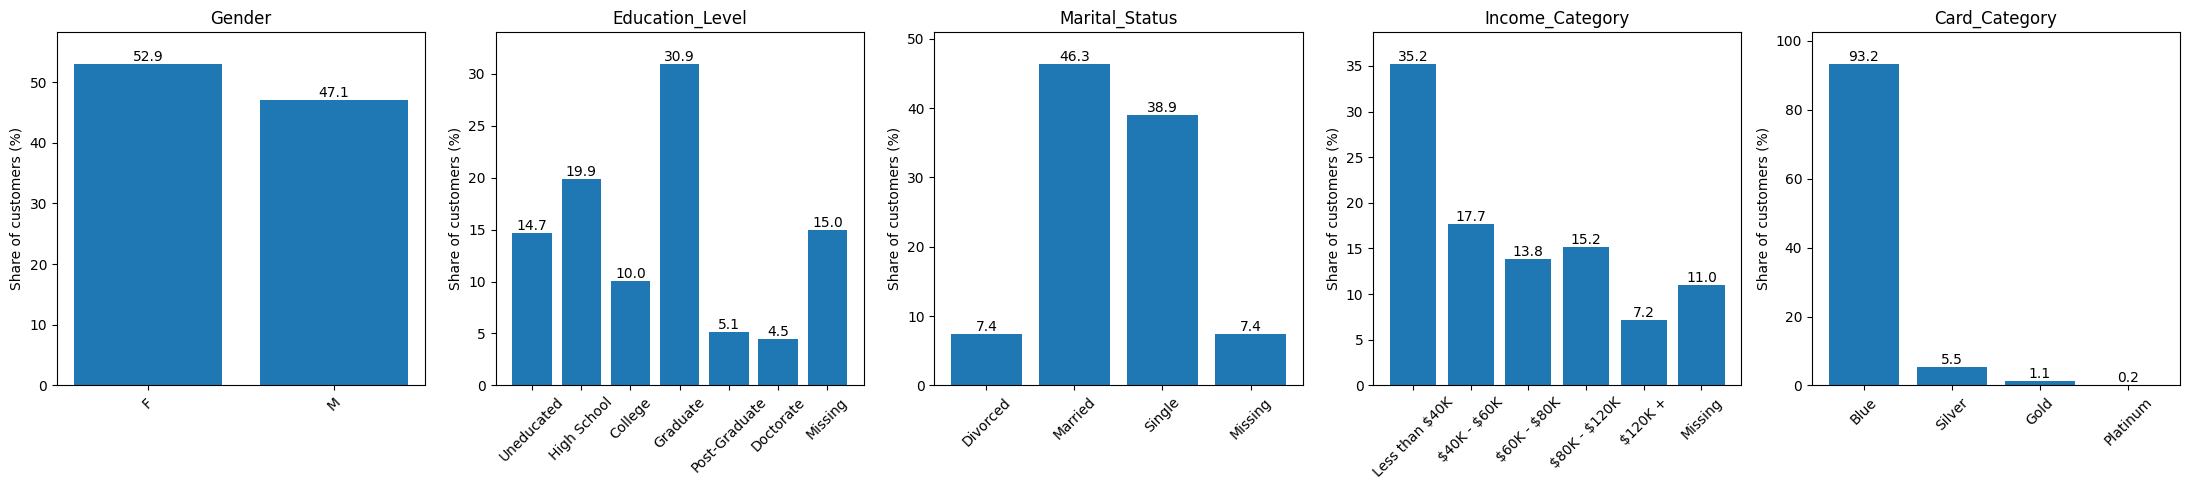

In [26]:
plot_shares(cat_cols, figsize=(22, 5), rotation=45)

`Gender` is almost balanced (52.9% women, 47.1% men). In the other variables a few categories dominate: Graduate in `Education_Level` (30.9%), Married and Single in `Marital_Status` (46.3% and 38.9%), and "Less than \$40K" in `Income_Category` (35.2%). Post-Graduate and Doctorate (5.1% and 4.5%), Divorced (7.4%) and "\$120K +" (7.2%) are small, but still large enough to be useful.

The "Missing" bars are as large as real categories. Missing education (15.0%) is bigger than College (10.0%) and about as big as Uneducated (14.7%), missing income (11.0%) is bigger than the highest income band, and missing marital status (7.4%) is as large as Divorced. The missing values therefore cannot be ignored, and how to handle them is decided after the churn comparison.

`Card_Category` is the real problem: 93.2% of the customers have a Blue card, and Gold and Platinum together make up only 1.3%. Such a variable carries very little information for clustering. After one-hot encoding, Platinum would become a column with only 20 customers, which could produce a tiny cluster of its own or simply add noise. A reasonable option is to merge the higher card tiers into one category, or to leave the variable out of the clustering and use it only to describe the clusters.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Bivariate Analysis: Churn by Counts and Categorical Variables </font></h2>
</div>

This section compares the churn rate between the values of each count and categorical variable. Because `Churned` is 1 for a closed account and 0 otherwise, the mean of `Churned` in a group is the share of customers in that group who closed their account.

Each bar shows the churn rate of one value together with the number of customers it is based on, and the dashed line marks the churn rate of all customers. Missing values are again a separate group "Missing", so that their churn rate can be compared with the known values.

In [27]:
overall_churn = df["Churned"].mean() * 100
print(f"Overall churn rate: {overall_churn:.1f}%")


def plot_churn_rates(cols, figsize, rotation=0):
    fig, axes = plt.subplots(1, len(cols), figsize=figsize)

    for ax, col in zip(axes, cols):
        groups = df.groupby(col, observed=False)["Churned"]
        rates = groups.mean() * 100
        sizes = groups.size()
        # escape "$", otherwise matplotlib reads "$40K - $60K" as a formula
        rates.index = rates.index.astype(str).str.replace("$", r"\$", regex=False)
        sizes.index = rates.index
        if df[col].isna().any():
            rates["Missing"] = df.loc[df[col].isna(), "Churned"].mean() * 100
            sizes["Missing"] = df[col].isna().sum()

        bars = ax.bar(rates.index, rates.values)
        ax.bar_label(bars, labels=[f"{rate:.1f}\n(n={size})" for rate, size in zip(rates, sizes)], fontsize=8)
        ax.axhline(overall_churn, color="gray", linestyle="--")
        ax.margins(y=0.2)
        ax.set_title(col)
        ax.set_ylabel("Churn rate (%)")
        ax.tick_params(axis="x", rotation=rotation)

    plt.tight_layout()
    plt.show()

Overall churn rate: 16.1%


### Small counts

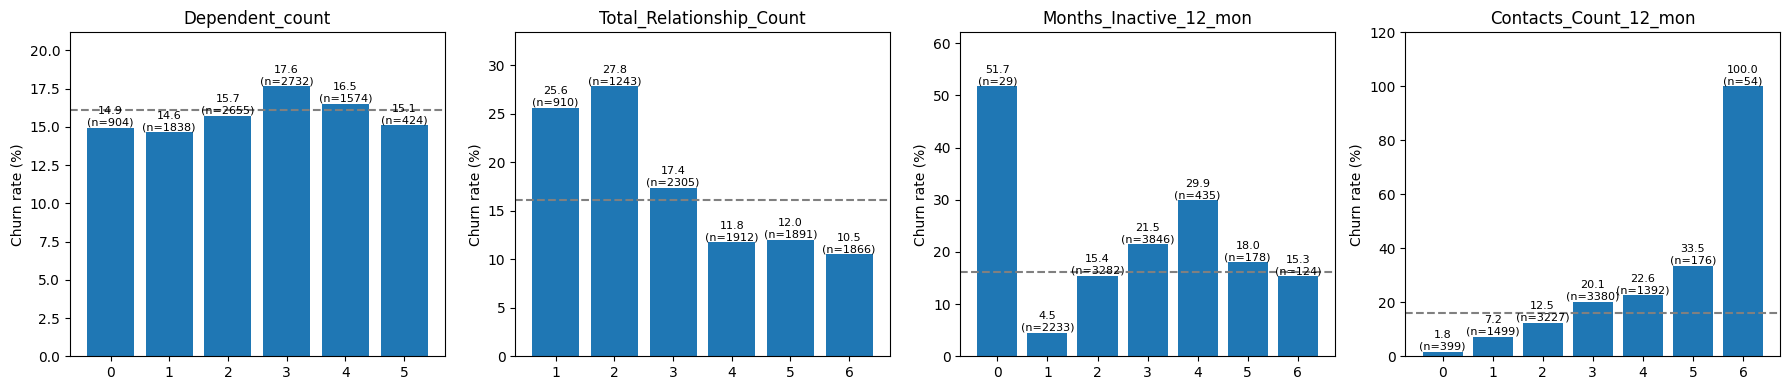

In [28]:
plot_churn_rates(count_cols, figsize=(18, 4))

Three of the four counts are clearly related to churn:
- `Total_Relationship_Count`: customers with 1 or 2 products churn much more often (25.6% and 27.8%) than customers with 4 to 6 products (10.5% to 12.0%). The more products a customer holds, the less likely they are to leave.
- `Contacts_Count_12_mon`: the churn rate rises steadily with the number of contacts, from 1.8% with no contact to 33.5% with 5 contacts, and all 54 customers with 6 contacts closed their account. The data cannot tell whether many contacts lead to churn or whether contacts made while leaving are also counted, so this variable describes the churn process at least as much as it predicts it.
- `Months_Inactive_12_mon`: the churn rate rises from 4.5% after 1 inactive month to 29.9% after 4 months. The values 5 and 6 break this trend, but they are based on only 178 and 124 customers.

`Dependent_count` shows no real effect: all its values lie between 14.6% and 17.6%, close to the overall rate.

The least reliable values are 0 inactive months (51.7%, but only 29 customers) and, to a lesser extent, 5 and 6 inactive months. The 100% for 6 contacts is also based on few customers (54), but a result this extreme is unlikely to be a coincidence.

### Categorical variables

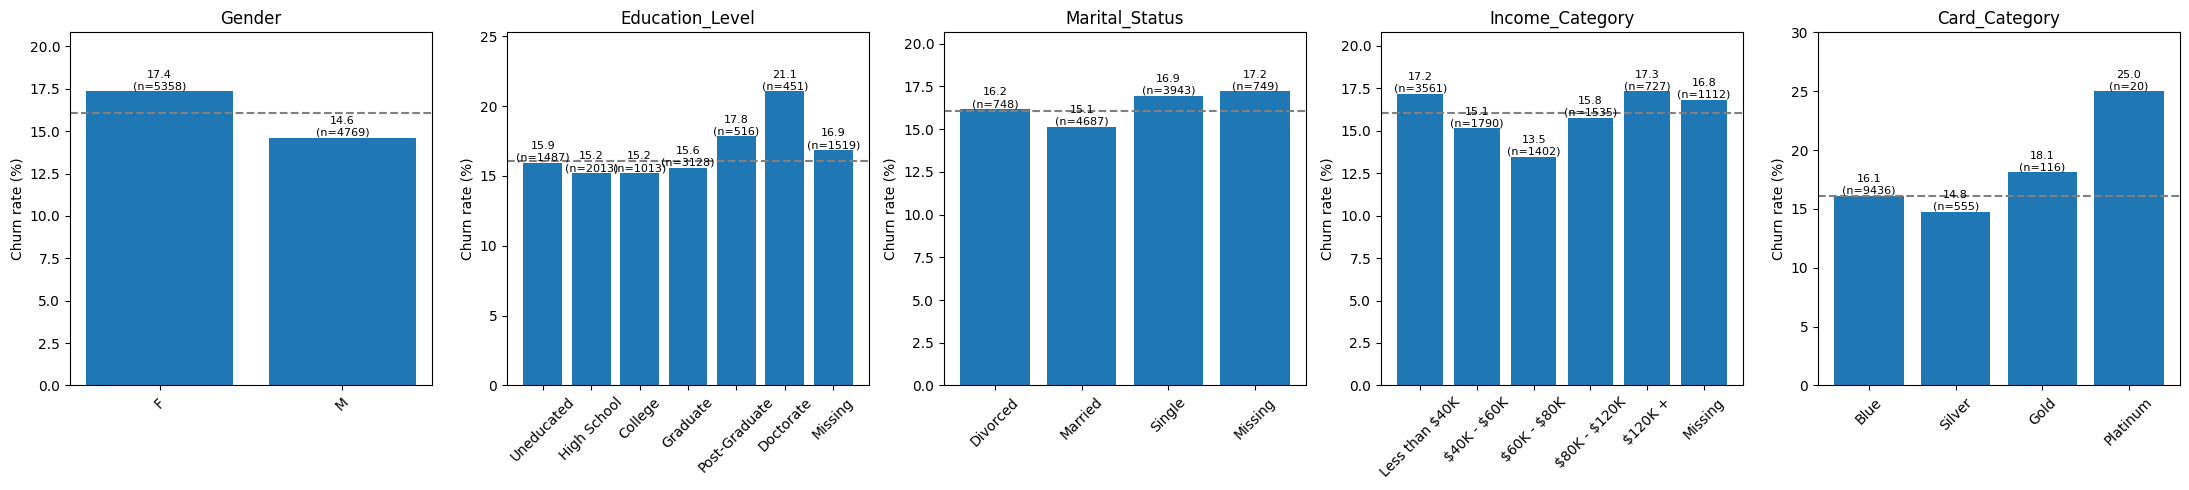

In [29]:
plot_churn_rates(cat_cols, figsize=(22, 5), rotation=45)

The categorical variables differ much less than the counts. Women churn slightly more often than men (17.4% vs 14.6%). In `Education_Level` the churn rate is close to average for most levels and higher only for Post-Graduate (17.8%) and Doctorate (21.1%). `Marital_Status` and `Income_Category` show no clear pattern: their rates lie between 13.5% and 17.3% and do not rise or fall with income. The demographic variables therefore say much less about churn than the behaviour of the customer.

The customers with missing values churn almost exactly like the others: 16.9% for missing education, 17.2% for missing marital status and 16.8% for missing income, all close to the overall rate of 16.1% and within the range of the known categories. A missing value is therefore not a sign of a different kind of customer, and handling the missing values does not risk removing a churn signal.

The only categories too small to trust are the higher card tiers: Platinum (25.0%) is based on only 20 customers and Gold (18.1%) on 116. Their rates cannot be distinguished from the overall rate, which supports merging these tiers or leaving `Card_Category` out of the clustering.

<div style="background-color: #05c3de; padding: 20px;">
    <h2><font color='white'> Bivariate Analysis: Churn by Continuous Variables </font></h2>
</div>

This section compares the continuous variables between customers who stayed and customers who closed their account. Because most of these variables are skewed, the groups are compared by their medians rather than their means.

In [30]:
median_by_churn = df.groupby("Churned")[cont_cols].median().T
median_by_churn.columns = ["Stayed (0)", "Churned (1)"]

display(median_by_churn)

,Stayed (0),Churned (1)
Customer_Age,46.000,47.000
Months_on_book,36.000,36.000
Credit_Limit,4643.500,4178.000
Total_Revolving_Bal,1364.000,0.000
Total_Amt_Chng_Q4_Q1,0.743,0.701
Total_Trans_Amt,4100.000,2329.000
Total_Trans_Ct,71.000,43.000
Total_Ct_Chng_Q4_Q1,0.721,0.531


The medians show only the centre of each group, so the full distributions are compared as well. Only 16.1% of the customers churned, so with plain counts their histogram would be much lower than the other one and hard to compare. Each group is therefore scaled separately to the same total area (`stat="density"` with `common_norm=False`), which compares the shapes of the two groups, not their sizes. The whole-number variables again get one bar per value.

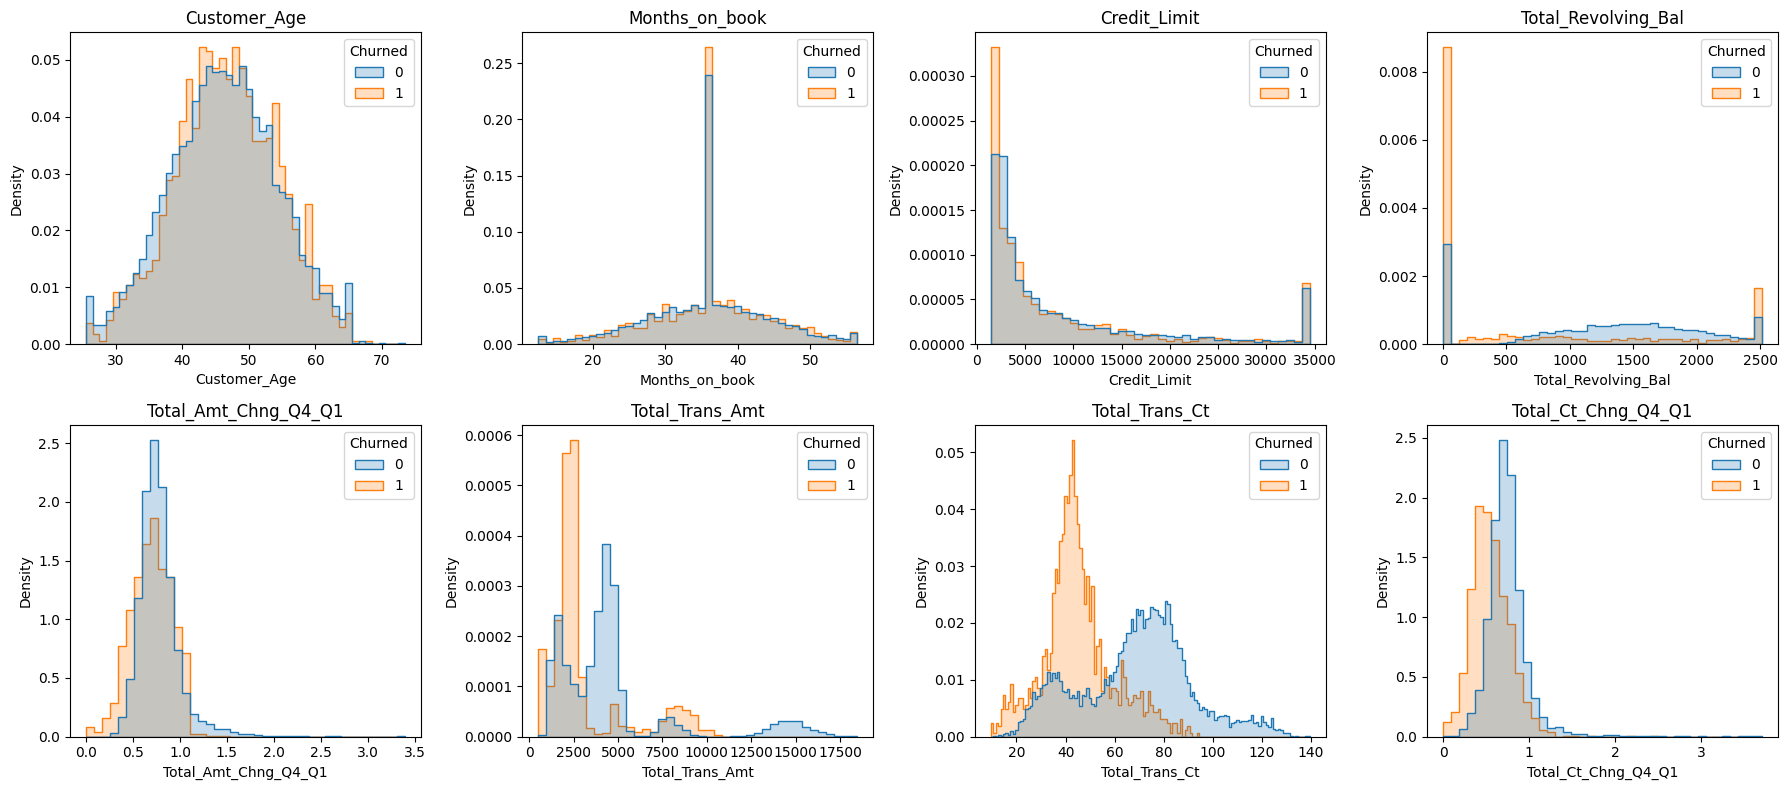

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flat, cont_cols):
    binning = {"discrete": True} if col in int_cols else {"bins": 40}
    sns.histplot(data=df, x=col, hue="Churned", stat="density", common_norm=False,
                 element="step", ax=ax, **binning)
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Q:** For which variables do the churned customers clearly differ from those who stayed, and in which direction?
-

**Q:** Which variables show hardly any difference?
-

**Q:** Do the patterns found in the univariate analysis churn differently: the group with zero revolving balance, the separate groups in `Total_Trans_Amt` and the two peaks in `Total_Trans_Ct`, and the customers with a sharp drop in the Q4/Q1 ratios?
-